In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

In [19]:
years = range(2020, 2027)

dfs = []

for year in years:
    file = f"TS_{year}.xlsx"
    df_temp = pd.read_excel(file, header=5)
    dfs.append(df_temp)

df = pd.concat(dfs, ignore_index=True)

df.columns = df.columns.str.strip()

print("Các cột:")
print(df.columns.tolist())

print("Kích thước:", df.shape)
print(df["Khóa học"].value_counts().sort_index())

Các cột:
['STT', 'Mã hồ sơ', 'Mã HS-SV', 'Họ đệm', 'Tên', 'Giới tính', 'Ngày sinh', 'Ngày nhập học', 'Nơi sinh', 'Quê quán', 'Nơi sinh Quận/Huyện', 'Nơi sinh Phường/Xã', 'DCLL_Số nhà', 'DCLL_Tỉnh', 'DCLL_Huyện', 'DCLL_Xã', 'HKTT_Số nhà', 'HKTT_Tỉnh', 'HKTT_Huyện', 'HKTT_Xã', 'Dân tộc', 'Tôn giáo', 'Hộ khẩu thường trú', 'Địa chỉ liên lạc', 'Tên đối tượng', 'Tên đối tượng chính sách', 'Khu vực', 'Tên tỉnh THPT', 'Tên huyện THPT', 'Tên phân hệ', 'Trường tốt nghiệp', 'Ngày vào Đoàn', 'Ngày vào Đảng', 'Số CMND', 'Ngày cấp', 'Nơi cấp', 'Mã lớp', 'Tên lớp', 'Khóa học', 'Bậc đào tạo', 'Loại đào tạo', 'Ngành', 'Nghề', 'Niên khóa', 'Họ tên cha', 'Nghề nghiệp', 'Họ tên Mẹ', 'Nghề nghiệp2', 'Điện thoại', 'Điện thoại phụ huynh', 'Email', 'Số quyết định', 'Trạng thái', 'Quốc tịch', 'Mã BHXH/ BYYT', 'Ghi chú', 'Nghề nghiệp.1']
Kích thước: (35716, 57)
Khóa học
2020.0    7378
2021.0    4684
2022.0    5870
2023.0    6311
2024.0    4308
2025.0    2999
2026.0    4159
Name: count, dtype: int64


TỔNG QUAN DATA

In [3]:
df2020.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7379 entries, 0 to 7378
Data columns (total 56 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   STT                       7378 non-null   float64
 1   Mã hồ sơ                  7378 non-null   object 
 2   Mã HS-SV                  7378 non-null   float64
 3   Họ đệm                    7378 non-null   object 
 4   Tên                       7378 non-null   object 
 5   Giới tính                 7378 non-null   object 
 6   Ngày sinh                 7378 non-null   object 
 7   Ngày nhập học             6690 non-null   object 
 8   Nơi sinh                  7330 non-null   object 
 9   Quê quán                  7330 non-null   object 
 10  Nơi sinh Quận/Huyện       5504 non-null   object 
 11  Nơi sinh Phường/Xã        259 non-null    object 
 12  DCLL_Số nhà               434 non-null    object 
 13  DCLL_Tỉnh                 668 non-null    object 
 14  DCLL_Huy

In [4]:
schema_summary = pd.DataFrame({
    'Column Name': df2020.columns,
    'Data Type': df2020.dtypes.values,
    'Non-Null Count': df2020.notnull().sum().values,
    'Null Count': df2020.isnull().sum().values,
    'Total Rows': len(df2020)
})

schema_summary.insert(0, 'No.', range(1, len(schema_summary) + 1))

print(schema_summary.to_string(index=False))

 No.              Column Name Data Type  Non-Null Count  Null Count  Total Rows
   1                      STT   float64            7378           1        7379
   2                 Mã hồ sơ    object            7378           1        7379
   3                 Mã HS-SV   float64            7378           1        7379
   4                   Họ đệm    object            7378           1        7379
   5                      Tên    object            7378           1        7379
   6                Giới tính    object            7378           1        7379
   7                Ngày sinh    object            7378           1        7379
   8            Ngày nhập học    object            6690         689        7379
   9                 Nơi sinh    object            7330          49        7379
  10                 Quê quán    object            7330          49        7379
  11      Nơi sinh Quận/Huyện    object            5504        1875        7379
  12       Nơi sinh Phường/Xã    object 

Trùng?

In [5]:
df2020.duplicated().sum()

np.int64(0)

Các trị duy nhất

In [6]:
unique = df2020.nunique().sort_values()
unique

Tên phân hệ                    1
Khóa học                       1
Bậc đào tạo                    2
Giới tính                      2
Niên khóa                      3
Khu vực                        4
Ngày vào Đảng                  5
Tên đối tượng                  7
Trạng thái                     7
Loại đào tạo                   8
Tôn giáo                      13
Tên đối tượng chính sách      15
Dân tộc                       21
Ngày vào Đoàn                 27
DCLL_Tỉnh                     36
Quốc tịch                     41
Ngành                         41
Nghề                          50
HKTT_Tỉnh                     55
Nơi sinh                      60
Tên tỉnh THPT                 64
Quê quán                      64
DCLL_Huyện                   138
Tên lớp                      152
Mã lớp                       152
Số quyết định                222
Nơi sinh Phường/Xã           229
Ngày nhập học                232
DCLL_Xã                      276
Nghề nghiệp2                 299
Nơi sinh Q

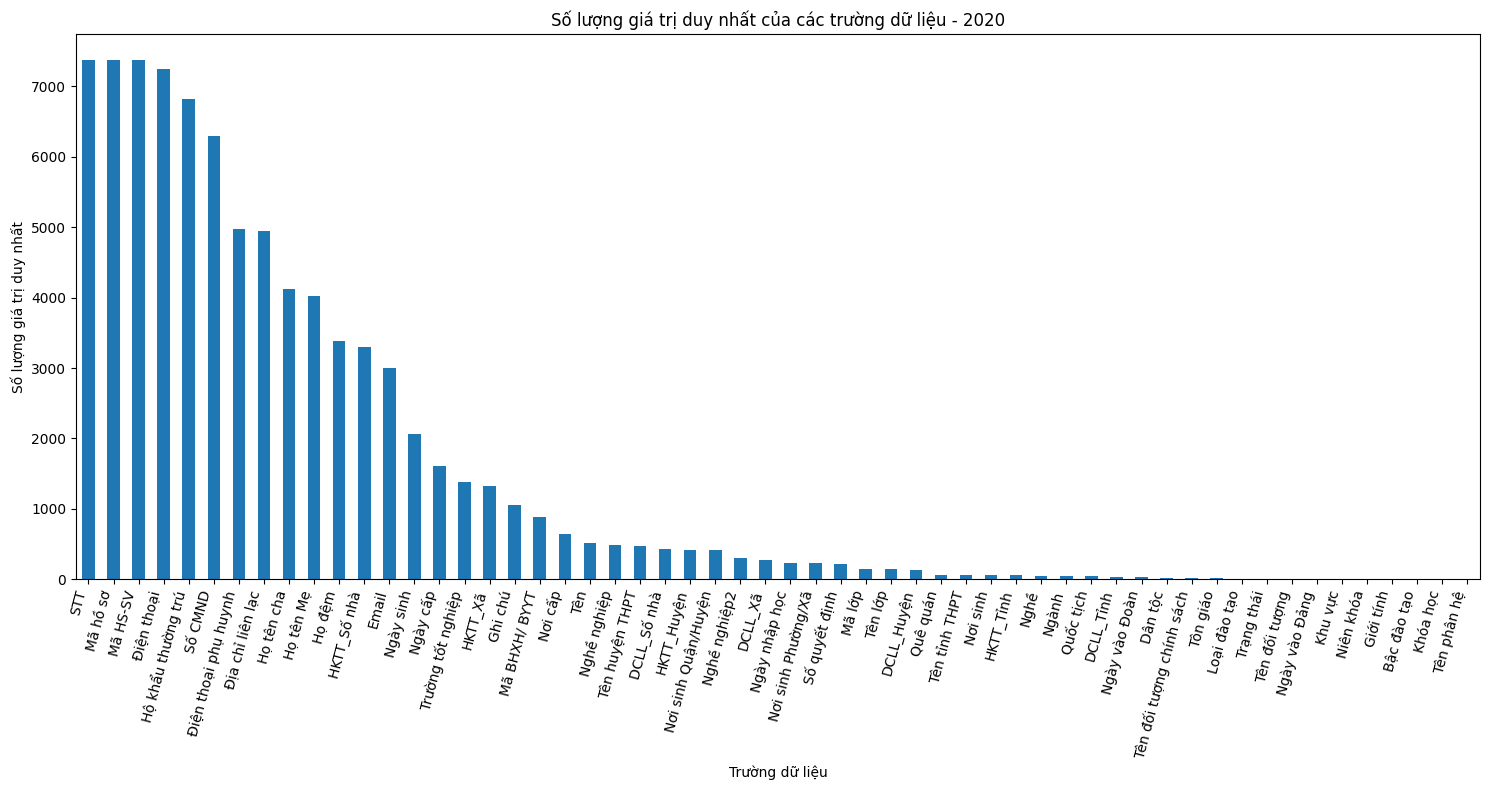

In [27]:

unique_count = (
    df2020.nunique()
    .sort_values(ascending=False)
)

plt.figure(figsize=(15, 8))

unique_count.plot(kind="bar")

plt.title("Số lượng giá trị duy nhất của các trường dữ liệu - 2020")
plt.xlabel("Trường dữ liệu")
plt.ylabel("Số lượng giá trị duy nhất")
plt.xticks(rotation=75, ha="right")

plt.tight_layout()
plt.show()

In [ ]:
for col in df2020.columns:
    values = df2020[col].dropna().unique()
    
    print(f"\n--- {col} ---")
    print(f"Số lượng unique: {len(values)}")
    
    if len(values) <= 30:
        print(values)
    else:
        print(values[:30])
        print("... (còn nhiều giá trị khác)")

Khảo sát các cột unqiue value ít có thể có tiềm năng phân tích

In [8]:
for col in df2020.columns:
    if df2020[col].nunique() <= 80:
        print(f"\n--- {col} ({df2020[col].nunique()} unique) ---")
        print(df2020[col].value_counts(dropna=False))


--- Giới tính (2 unique) ---
Giới tính
Nam    6116
Nữ     1262
NaN       1
Name: count, dtype: int64

--- Nơi sinh (60 unique) ---
Nơi sinh
Tp. Hồ Chí Minh (Đến ngày 01-07-2025)       3533
Long An (Đến ngày 01-07-2025)                321
Tiền Giang (Đến ngày 01-07-2025)             237
Tây Ninh (Đến ngày 01-07-2025)               233
Đồng Nai (Đến ngày 01-07-2025)               205
                                            ... 
Campuchia (Đến ngày 01-07-2025)                1
Lào Cai (Đến ngày 01-07-2025)                  1
Hà Nội (Hà tây cũ) (Đến ngày 01-07-2025)       1
Tuyên Quang (Đến ngày 01-07-2025)              1
Yên Bái (Đến ngày 01-07-2025)                  1
Name: count, Length: 61, dtype: int64

--- Quê quán (64 unique) ---
Quê quán
Tp. Hồ Chí Minh    2762
Long An             393
Tiền Giang          271
Quảng Ngãi          259
Bến Tre             256
                   ... 
Lào Cai               2
Hoà Bình              2
Lai Châu              1
Nam Hà                1
Tuy

Những cột giữ lại và trực quan

In [9]:
keep_cols = [
    "Giới tính", "Ngày sinh", "Ngày nhập học",
    "Quê quán", "HKTT_Tỉnh", "HKTT_Huyện","HKTT_Xã", "Khu vực",
    "Tên tỉnh THPT", "Tên huyện THPT", "Trường tốt nghiệp",
    "Khóa học", "Bậc đào tạo", "Loại đào tạo",
    "Ngành", "Nghề", "Niên khóa", "Trạng thái",
    "Quốc tịch", "Ghi chú"
]

In [10]:
df_analysis = df2020[keep_cols].copy()

In [11]:
df_analysis.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7379 entries, 0 to 7378
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Giới tính          7378 non-null   object 
 1   Ngày sinh          7378 non-null   object 
 2   Ngày nhập học      6690 non-null   object 
 3   Quê quán           7330 non-null   object 
 4   HKTT_Tỉnh          6010 non-null   object 
 5   HKTT_Huyện         5979 non-null   object 
 6   HKTT_Xã            5011 non-null   object 
 7   Khu vực            6093 non-null   object 
 8   Tên tỉnh THPT      7330 non-null   object 
 9   Tên huyện THPT     6015 non-null   object 
 10  Trường tốt nghiệp  6541 non-null   object 
 11  Khóa học           7378 non-null   float64
 12  Bậc đào tạo        7378 non-null   object 
 13  Loại đào tạo       7378 non-null   object 
 14  Ngành              7378 non-null   object 
 15  Nghề               7378 non-null   object 
 16  Niên khóa          7378 

In [12]:
print("Số bản ghi trùng:", df_analysis.duplicated().sum())

Số bản ghi trùng: 7


In [13]:
schema_summary = pd.DataFrame({
    'Column Name': df_analysis.columns,
    'Data Type': df_analysis.dtypes.values,
    'Non-Null Count': df_analysis.notnull().sum().values,
    'Null Count': df_analysis.isnull().sum().values,
    'Total Rows': len(df_analysis)
})

schema_summary.insert(0, 'No.', range(1, len(schema_summary) + 1))

print(schema_summary.to_string(index=False))

 No.       Column Name Data Type  Non-Null Count  Null Count  Total Rows
   1         Giới tính    object            7378           1        7379
   2         Ngày sinh    object            7378           1        7379
   3     Ngày nhập học    object            6690         689        7379
   4          Quê quán    object            7330          49        7379
   5         HKTT_Tỉnh    object            6010        1369        7379
   6        HKTT_Huyện    object            5979        1400        7379
   7           HKTT_Xã    object            5011        2368        7379
   8           Khu vực    object            6093        1286        7379
   9     Tên tỉnh THPT    object            7330          49        7379
  10    Tên huyện THPT    object            6015        1364        7379
  11 Trường tốt nghiệp    object            6541         838        7379
  12          Khóa học   float64            7378           1        7379
  13       Bậc đào tạo    object            7378   

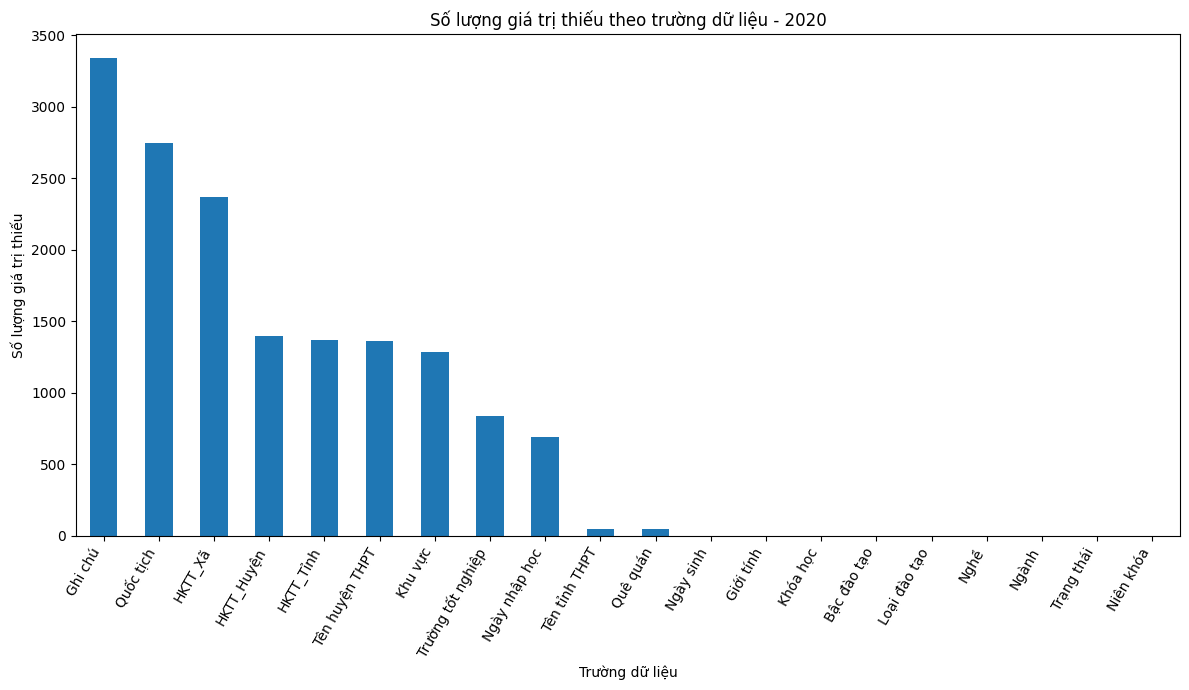

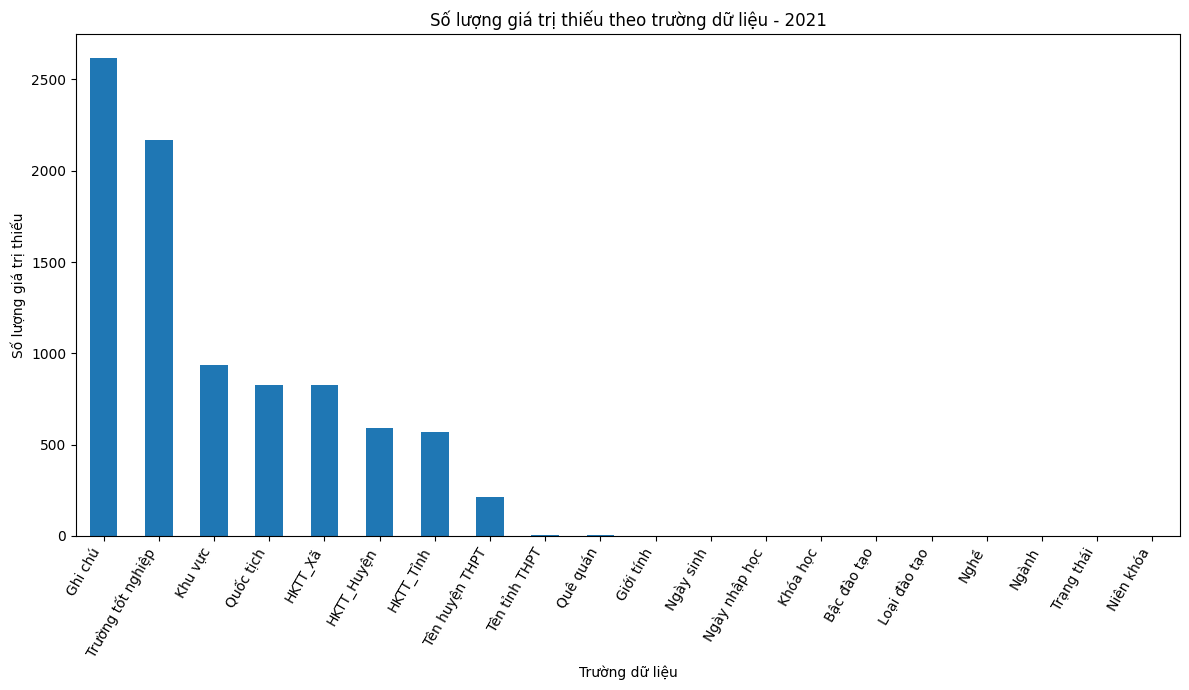

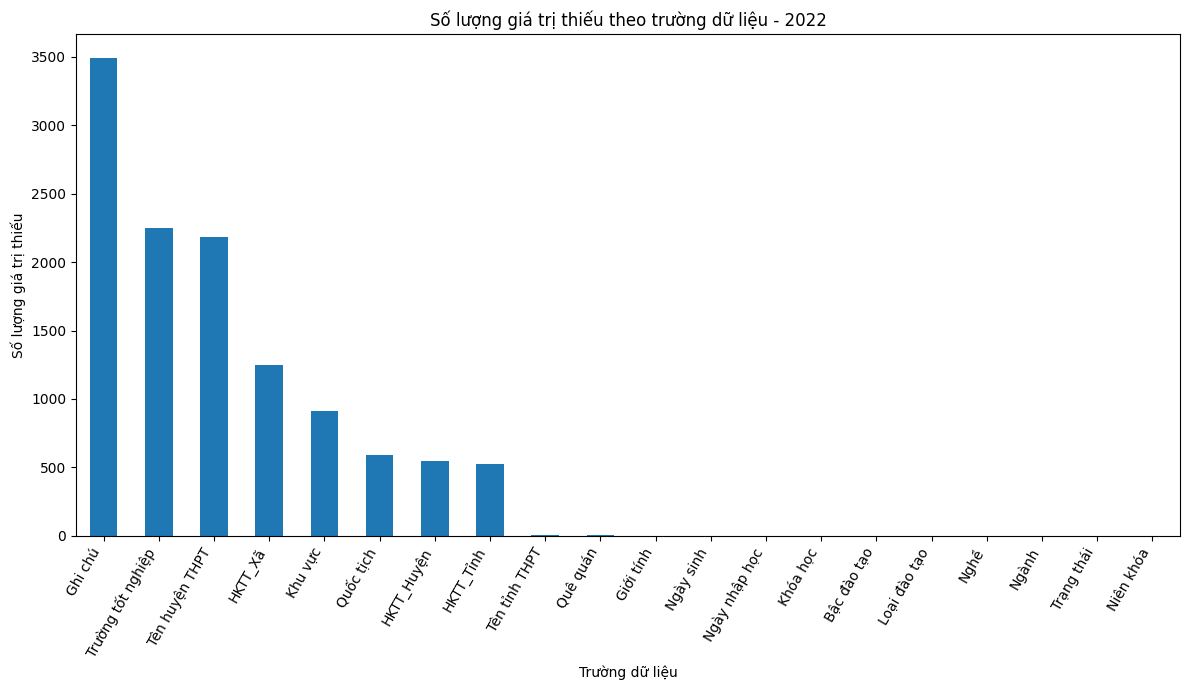

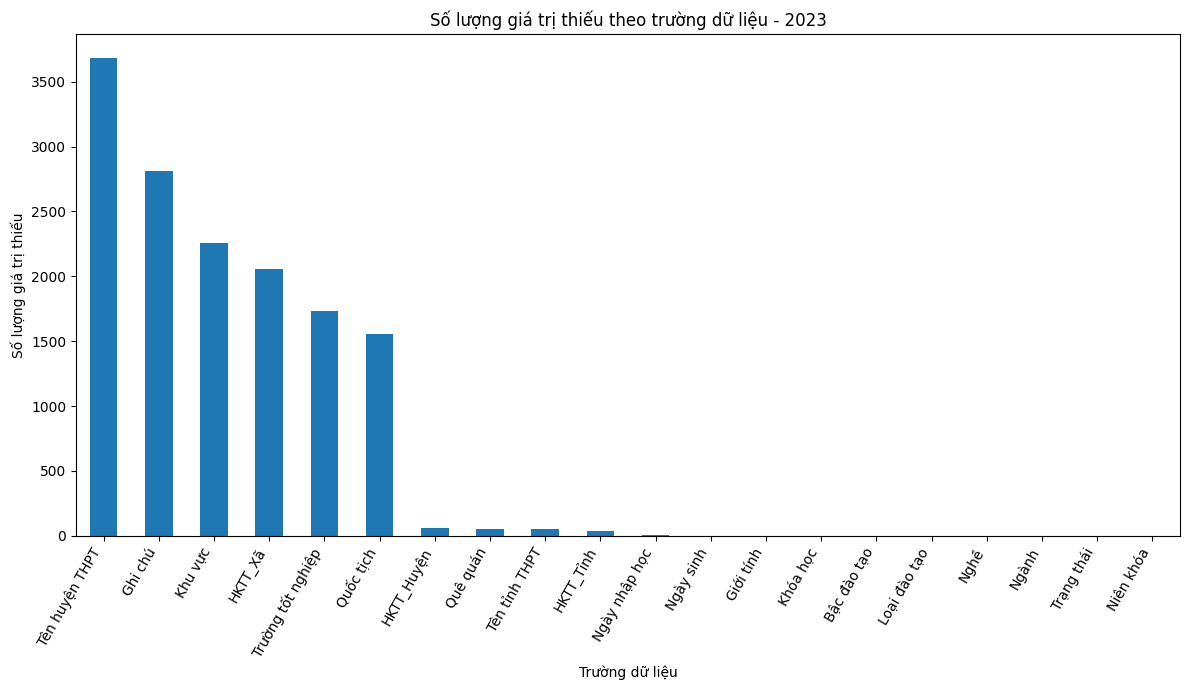

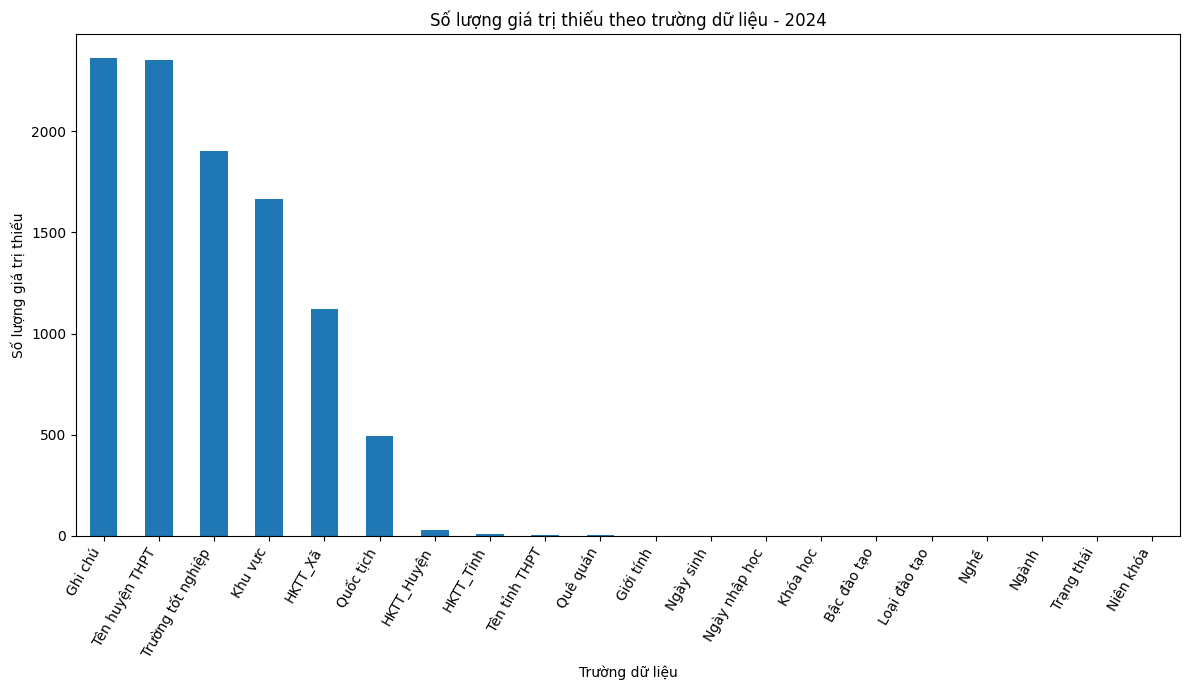

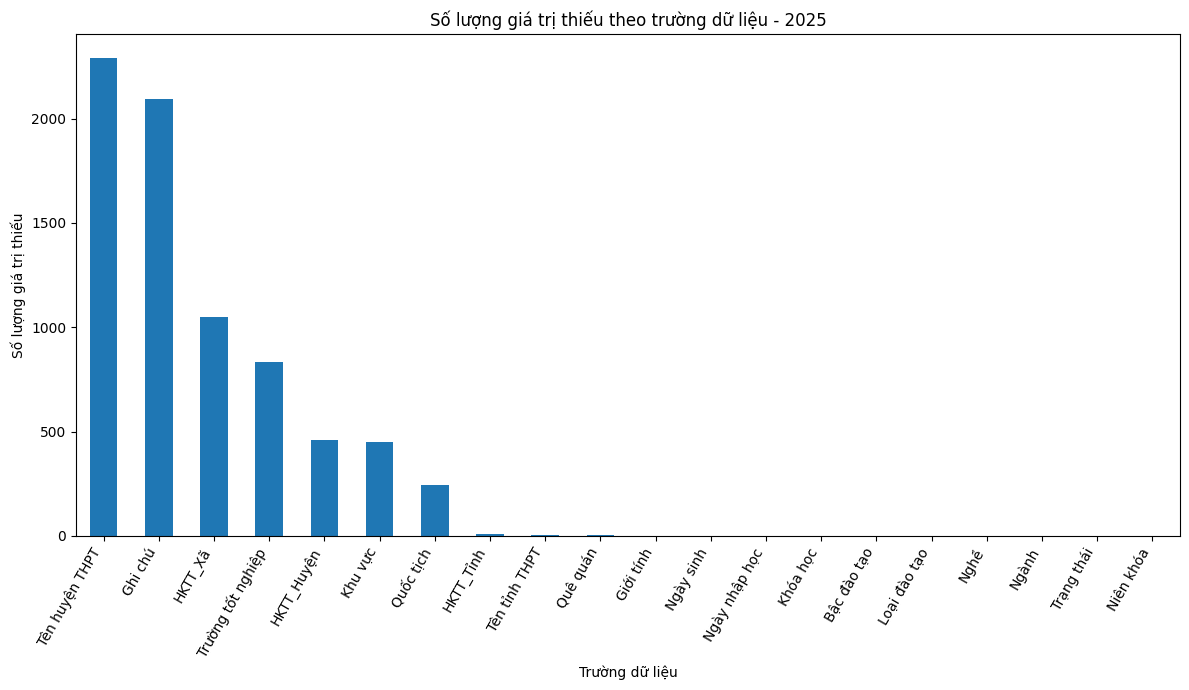

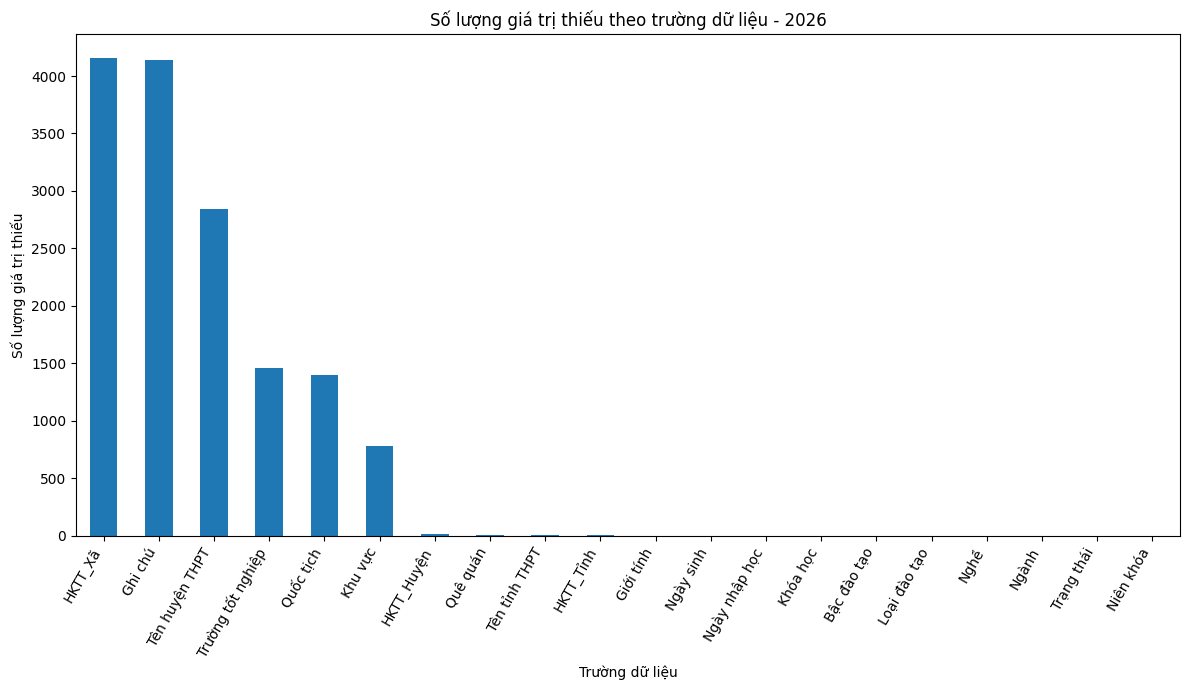

In [25]:
import matplotlib.pyplot as plt

selected_cols = [
    "Giới tính", "Ngày sinh", "Ngày nhập học",
    "Quê quán", "HKTT_Tỉnh", "HKTT_Huyện", "HKTT_Xã", "Khu vực",
    "Tên tỉnh THPT", "Tên huyện THPT", "Trường tốt nghiệp",
    "Khóa học", "Bậc đào tạo", "Loại đào tạo",
    "Ngành", "Nghề", "Niên khóa", "Trạng thái",
    "Quốc tịch", "Ghi chú"
]

for year in range(2020, 2027):
    
    df_year = df[df["Khóa học"] == year]
    
    missing = (
        df_year[selected_cols]
        .isna()
        .sum()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(12, 7))
    
    missing.plot(kind="bar")
    
    plt.title(f"Số lượng giá trị thiếu theo trường dữ liệu - {year}")
    plt.xlabel("Trường dữ liệu")
    plt.ylabel("Số lượng giá trị thiếu")
    plt.xticks(rotation=60, ha="right")
    
    plt.tight_layout()
    plt.show()